## Beskrivande Analys
Vi sammanfattar ålder, vikt, längd, systoliskt blodtryck och kolesterol med medelvärde, median, minimi- och maximivärde. Det hjälper oss att förstå datans nivå och spridning. 

## Datakonroll

In [9]:
print("Antal deltagare och variabler:", df.shape)

print("\nSaknade värden:")
print(df.isna().sum())

print("\nAntal dubblettrader:", df.duplicated().sum())

variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]
print("\nDatatyper:")

print(df[variabler].dtypes)

Antal deltagare och variabler: (800, 9)

Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Antal dubblettrader: 0

Datatyper:
age              int64
weight         float64
height         float64
systolic_bp    float64
cholesterol    float64
dtype: object


In [10]:
import pandas as pd 

df = pd.read_csv("../data/health_study_dataset.csv")

variabler = ["age", "weight", "height", "systolic_bp", "cholesterol"]

sammanfattning = df[variabler].agg(["mean", "median", "min", "max"]).T

sammanfattning = sammanfattning.rename(
    index={
        "age": "Ålder (år)",
        "weight": "Vikt (kg)",
        "height": "Längd (cm)",
        "systolic_bp": "Systoliskt blodtryck (mmHg)",
        "cholesterol": "Kolesterol (mmol/L)",
    },
    columns={
        "mean": "Medelvärde",
        "median": "Median",
        "min": "Min",
        "max": "Max",
    },
)

sammanfattning.round(2)

,Medelvärde,Median,Min,Max
Ålder (år),49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


## Grafer 
Graferna hjälper oss att se hur värdena är fördelade och jämför grupper. Vi visar blodtryckens fördelning, vikt per kön och andelen rökare. 

## 1. Histogram över systoliskt blodtryck

Ett histogram delar in blodtrycksvärdena i intervall. Stapelhöjden visar hur många deltagare som har värden i varje intervall. 

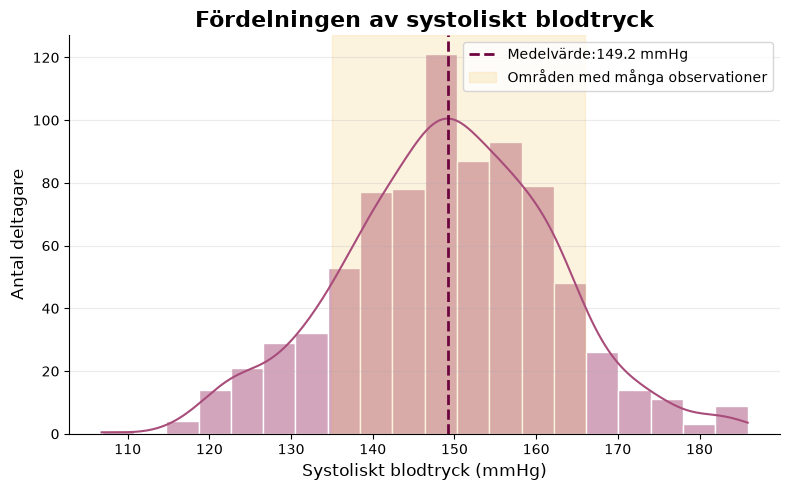

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(
    data=df, 
    x="systolic_bp", 
    bins=20, 
    kde=True,
    color="#A84C7A",
    edgecolor="white",
    linewidth=1
)

medel=df["systolic_bp"].mean()
plt.axvline(medel, color="#6E043F", linestyle="--", linewidth=2,
            label=f"Medelvärde:{medel:.1f} mmHg")

plt.axvspan(135, 166, color="#F2C14E", alpha=0.18,
            label="Centralt område (135-167 mmHg)")

plt.title("Fördelningen av systoliskt blodtryck", fontsize=16, weight="bold")
plt.xlabel("Systoliskt blodtryck (mmHg)", fontsize=12)
plt.ylabel("Antal deltagare", fontsize=12)
plt.legend()
plt.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

Histogramet visar att deltagarnas systoliska blodtryck främst är koncentrerat kring 150mmHg. De flesta observationerna ligger ungefär mellan 135 och 167 mmHg, medan det finns färre deltagare med lägre och högre värden. Medelvärdet är cirka 149,2 mmHg. Detta beskriver fördelningen i det här datasetet. 

## Boxplot över vikt per kön 

Boxploten jämför viktens median och spridning mellan grupperna. Punkten utanför "lådan" kan vara ovanliga värden.

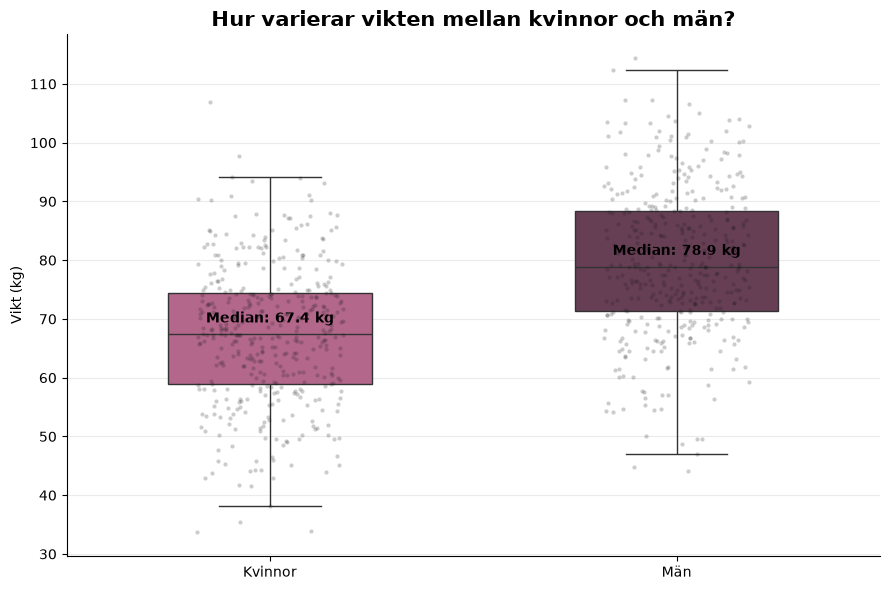

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Skapa tydliga gruppnamn från F och M.
df["kön_namn"] = df["sex"].map({"F": "Kvinnor", "M": "Män"})
ordning = ["Kvinnor", "Män"]

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="kön_namn",
    y="weight",
    hue="kön_namn",
    order=ordning,
    palette=["#C05A8A", "#6E3856"],
    width=0.5,
    showfliers=False,
    ax=ax
)

# Lägg till enskilda deltagares vikter som svaga prickar.
sns.stripplot(
    data=df,
    x="kön_namn",
    y="weight",
    order=ordning,
    color="#1B1A1A",
    alpha=0.22,
    size=3,
    jitter=0.18,
    ax=ax
)

# Skriv medianen ovanför varje box.
medianer = df.groupby("kön_namn")["weight"].median()

for position, grupp in enumerate(ordning):
    ax.text(
        position,
        medianer[grupp] + 2,
        f"Median: {medianer[grupp]:.1f} kg",
        ha="center",
        fontsize=10,
        weight="bold"
    )

ax.set_title("Hur varierar vikten mellan kvinnor och män?", fontsize=15, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Vikt (kg)")
ax.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

Medianvikten är högre bland män än bland kvinnor i detta dataset. Samtidigt varierar vikterna inom båda grupperna och överlappar, så diagrammet visar inte att varje man väger mer än varje kvinna. Det beskriver bara deltagarna i den här studien och visar inte vad som orsakar skillnaden. 

## 3. Stapeldiagram över andelen rökare

Först räknar vi andelen som svaret Yes respektive No. normalize=True gör om antal till andelar. Multiplikation med 
100 ger procent.

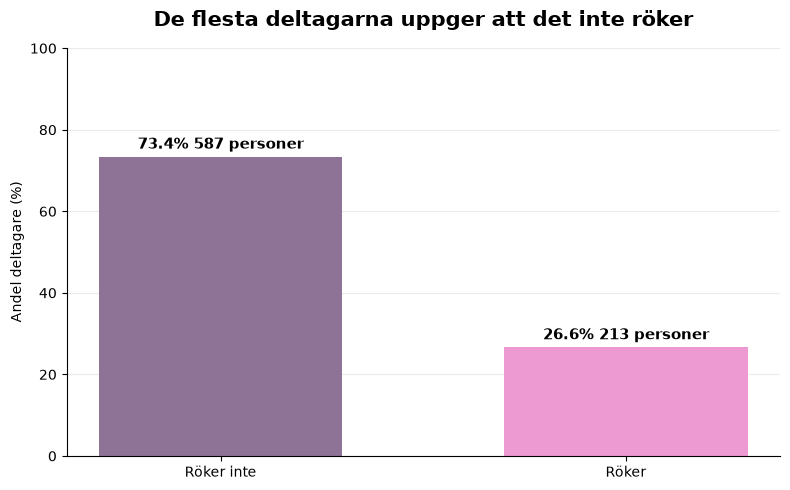

In [38]:
antal = df["smoker"]. value_counts().reindex(["No", "Yes"], fill_value=0)
procent = antal / antal.sum() * 100

namn = ["Röker inte", "Röker"]
färger = ["#8F7396", "#EC9AD1"]

fig, ax = plt.subplots(figsize=(8, 5))

staplar = ax.bar(
    namn,
    procent,
    color=färger,
    width=0.6
)

for stapel, pct, n in zip(staplar, procent, antal):
    ax.text(
        stapel.get_x() + stapel.get_width() / 2,
        stapel.get_height() + 2,
        f"{pct:.1f}% {n} personer",
        ha="center",
        fontsize=11,
        weight="bold" 
    )

ax.set_title("De flesta deltagarna uppger att det inte röker",
             fontsize=15, weight="bold", pad=16)
ax.set_ylabel("Andel deltagare (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Diagrammet visar att ungefär tre fjärdedelar av deltagarna uppger att de inte röker, medan ungefär en fjärdedel uppger att de röker. 
Procentsatserna gäller deltagarna i detta dataset.

## Simulering av sjudomsandel

Först räknar vi ut andelen deltagare med sjukdomen i datasetet. Sedan använder vi den andelen som sannolikhet i en simulering av 1000 personer. Ett fast slumpfrö gör att simuleringen ger samma resultat varje gång koden körs. 

In [35]:
import numpy as np 

verklig_andel = (df["disease"] == 1). mean()

np.random.seed(42)

simulerade_personer = np.random.binomial(
    n=1,
    p=verklig_andel,
    size=1000
)

simulerad_andel = simulerade_personer.mean()

print(f"Verklig andel i datasetet: {verklig_andel:.1%}")
print(f"Simulerad andel bland 1000 personer: {simulerad_andel:.1%}")
print(f"Skillnad: {abs(simulerad_andel - verklig_andel):.1%}")

Verklig andel i datasetet: 5.9%
Simulerad andel bland 1000 personer: 5.6%
Skillnad: 0.3%


I datasetet hade 5,9% av deltagarna sjukdomen. I simuleringen av 1000 slumpade personer blev andelen 5,6%
vilket är en skillnad på 0,3 procentenheter. Simuleringen hamnade alltså nära datasetets andel. 
Den lilla skillnaden beror på slumpen. 

## Konfidensintervall för systoliskt blodtryck 

Vi beräknar ett 95% konfidensintervall för medelvärdet med en normalapproximation. Metoden använder stickprovsmedelvärdet och dess standardfel. 
Vi antar att observationerna är oberoende och att urvalet är tillräckligt stort för att normalapproximationen ska fungera. 

In [36]:
blodtryck = df["systolic_bp"].dropna()

n = len(blodtryck)
medel = blodtryck.mean()
standardavvikelse = blodtryck.std(ddof=1)

standardfel = standardavvikelse / np.sqrt(n)

nedre_gräns = medel - 1.96 * standardfel 
övre_gräns = medel + 1.96 * standardfel 

print(f"Antal deltagare: {n}")
print(f"Medelvärde: {medel:.2f} mmHg")
print(f"95 % konfidensintervall: {nedre_gräns:.2f}--{övre_gräns:.2f}mmHg")



Antal deltagare: 800
Medelvärde: 149.18 mmHg
95 % konfidensintervall: 148.29--150.07mmHg


Medelblodtrycket bland de 800 deltagarna är 149,18 mmHg. Vårt 95% konfidensintervall är 148,29 - 150,07 mmHg.
Det visar osäkerheten i uppskattningen av medelvärdet. Intervallet gäller genomsnittet,
inte blodtrycket hos varje enskild deltagare. 

In [37]:
from scipy import stats

rökare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
icke_rökare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

resultat = stats.ttest_ind(
    rökare,
    icke_rökare,
    equal_var=False,
    alternative="greater"
)

print(f"Antal rökare: {len(rökare)}")
print(f"Antal icke-rökare: {len(icke_rökare)}")
print(f"Medelblodtryck för rökare: {rökare.mean():.2f} mmHg")
print(f"Medelblodtryck för icke_rökare: {icke_rökare.mean():.2f} mmHg")
print(f"t-värde: {resultat.statistic:.3f}")
print(f"p-värde: {resultat.pvalue:.4f}")

Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck för rökare: 149.52 mmHg
Medelblodtryck för icke_rökare: 149.05 mmHg
t-värde: 0.450
p-värde: 0.3264


Rökarnas medelblodtryck var 149,52 mmHg, jämfört med 149,05 mmHg för icke-rökare. Skillnaden var liten (0,47 mmHg). Welch t-testet gav p = 0,3264,
vilket är större än 0,05. Därför finns det inte tillräckligt statistikt stöd för att säga att rökare har högre medelblodtryck i detta dataset. 
Resultatet visar inte att rökning orsakar blodtrycksskillnad. 